#**Connect With Google Drive**

In [2]:

# ============================================================
# EXPERIMENT 06 — EXTERNAL FAILURE ANALYSIS
# CELL 1: GOOGLE DRIVE + INPUT FILE VERIFICATION
#
# Existing RETFound-Green results only
# No model training
# No recalibration
# No threshold modification
# No files overwritten
# ============================================================

from google.colab import drive
from pathlib import Path
import pandas as pd
import json

# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_DR")

assert PROJECT_DIR.is_dir(), (
    f"Project directory not found: {PROJECT_DIR}"
)

print("PROJECT DIRECTORY:", PROJECT_DIR)

# ============================================================
# 2. LOCK EXISTING EXPERIMENT SETTINGS
# ============================================================

SEEDS = [42, 43, 44, 45, 46]
ALPHA = 0.05

# ============================================================
# 3. EXISTING INPUT FILES
# ============================================================

APTOS_PRED_PATH = (
    PROJECT_DIR / "aptos_retfound_raw_predictions.csv"
)

IDRID_PRED_PATH = (
    PROJECT_DIR / "idrid_retfound_raw_predictions.csv"
)

MESSIDOR_PRED_PATH = (
    PROJECT_DIR / "messidor2_retfound_raw_predictions.csv"
)

TEMP_PATH = (
    PROJECT_DIR / "aptos_retfound_temperature_scaling.json"
)

LTT_PATH = (
    PROJECT_DIR / "aptos_retfound_ltt_risk_control.csv"
)

required_files = {
    "APTOS predictions": APTOS_PRED_PATH,
    "IDRiD predictions": IDRID_PRED_PATH,
    "Messidor-2 predictions": MESSIDOR_PRED_PATH,
    "APTOS temperatures": TEMP_PATH,
    "APTOS LTT policies": LTT_PATH
}

# ============================================================
# 4. VERIFY ALL FILES EXIST
# ============================================================

print("\n========== FILE VERIFICATION ==========")

missing = []

for name, path in required_files.items():

    if path.is_file():
        print(f"FOUND   | {name}")
    else:
        print(f"MISSING | {name}")
        missing.append(str(path))

if missing:
    raise FileNotFoundError(
        "Required files missing:\n" + "\n".join(missing)
    )

# ============================================================
# 5. VERIFY PREDICTION CSV COLUMNS
# ============================================================

required_columns = {
    "seed",
    "image_id",
    "original_grade",
    "binary_label",
    "raw_logit"
}

prediction_files = {
    "APTOS": APTOS_PRED_PATH,
    "IDRiD": IDRID_PRED_PATH,
    "Messidor-2": MESSIDOR_PRED_PATH
}

print("\n========== COLUMN VERIFICATION ==========")

for dataset, path in prediction_files.items():

    columns = set(
        pd.read_csv(path, nrows=0).columns
    )

    missing_columns = required_columns - columns

    if missing_columns:
        raise ValueError(
            f"{dataset} missing columns: "
            f"{sorted(missing_columns)}"
        )

    if dataset == "APTOS" and "split" not in columns:
        raise ValueError(
            "APTOS predictions missing 'split' column."
        )

    print(f"{dataset}: REQUIRED COLUMNS FOUND")

print("\nSETUP COMPLETE — ALL REQUIRED FILES VERIFIED")


Mounted at /content/drive
PROJECT DIRECTORY: /content/drive/MyDrive/thesis_DR

========== FILE VERIFICATION ==========
FOUND   | APTOS predictions
FOUND   | IDRiD predictions
FOUND   | Messidor-2 predictions
FOUND   | APTOS temperatures
FOUND   | APTOS LTT policies

========== COLUMN VERIFICATION ==========
APTOS: REQUIRED COLUMNS FOUND
IDRiD: REQUIRED COLUMNS FOUND
Messidor-2: REQUIRED COLUMNS FOUND

SETUP COMPLETE — ALL REQUIRED FILES VERIFIED


#**Load Dataset**



**Download Messidor-2**

In [5]:

# ============================================================
# DOWNLOAD MESSIDOR-2 TO TEMPORARY COLAB STORAGE
# ORIGINAL EXTERNAL VALIDATION NOTEBOOK — CELL 4
# ============================================================

!pip -q install gdown

from pathlib import Path
import zipfile
import gdown

ZIP_PATH = Path("/content/MESSIDOR2.zip")
DATA_DIR = Path("/content/MESSIDOR2")

# Original archive used in previous notebook
FILE_ID = "1vOLBUK9xdzNV8eVkRjVdNrRwhPfaOmda"

# Download
if not ZIP_PATH.exists():
    gdown.download(
        id=FILE_ID,
        output=str(ZIP_PATH),
        quiet=False
    )

# Extract
DATA_DIR.mkdir(parents=True, exist_ok=True)

if not any(DATA_DIR.iterdir()):
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(DATA_DIR)

print("\nMessidor-2 downloaded and extracted")
print("Dataset location:", DATA_DIR)

# Inspect dataset
all_files = [
    p for p in DATA_DIR.rglob("*")
    if p.is_file()
]

image_files = [
    p for p in all_files
    if p.suffix.lower()
    in [".jpg", ".jpeg", ".png", ".tif", ".tiff"]
]

print("Total files:", len(all_files))
print("Image files:", len(image_files))

print("\nTop-level contents:")
for p in DATA_DIR.iterdir():
    print(" -", p.name)


Downloading...
From (original): https://drive.google.com/uc?id=1vOLBUK9xdzNV8eVkRjVdNrRwhPfaOmda
From (redirected): https://drive.google.com/uc?id=1vOLBUK9xdzNV8eVkRjVdNrRwhPfaOmda&confirm=t&uuid=3bb04fd5-37b6-47f3-814d-b2b4dc652cc1
To: /content/MESSIDOR2.zip
100%|██████████| 2.51G/2.51G [00:54<00:00, 46.4MB/s]



Messidor-2 downloaded and extracted
Dataset location: /content/MESSIDOR2
Total files: 1745
Image files: 1744

Top-level contents:
 - MESSIDOR2


**Download IDRiD dataset**

In [6]:

# ============================================================
# DOWNLOAD FULL IDRiD DATASET + VERIFY
# ORIGINAL EXTERNAL VALIDATION NOTEBOOK — CELL 27
# ============================================================

!pip -q install kagglehub

from pathlib import Path
import kagglehub

# ============================================================
# DOWNLOAD
# ============================================================

path = Path(
    kagglehub.dataset_download(
        "dankok/diabetic-retinopathy-image-dataset"
    )
)

print("Downloaded to:")
print(path)

# ============================================================
# SHOW CSV FILES
# ============================================================

print("\n========== CSV FILES ==========\n")

csv_files = sorted(
    path.rglob("*.csv")
)

for p in csv_files:
    print(p)

# ============================================================
# FIND IDRiD JPG IMAGES
# ============================================================

jpg_files = sorted(
    [
        p for p in path.rglob("*")
        if p.suffix.lower() in {".jpg", ".jpeg"}
        and "IDRiD" in p.name
    ]
)

print(
    "\n========== IDRiD JPG FILES ==========\n"
)

print(
    "Total IDRiD JPG files found:",
    len(jpg_files)
)

print("\nFirst 15:")

for p in jpg_files[:15]:
    print(p)

# ============================================================
# SHOW MAIN DIRECTORY STRUCTURE
# ============================================================

print(
    "\n========== MAIN FOLDERS ==========\n"
)

for p in sorted(path.iterdir()):
    print(p)


100%|██████████| 408M/408M [00:22<00:00, 19.0MB/s]

Extracting files...


Downloaded to:
/root/.cache/kagglehub/datasets/dankok/diabetic-retinopathy-image-dataset/versions/1

========== CSV FILES ==========

/root/.cache/kagglehub/datasets/dankok/diabetic-retinopathy-image-dataset/versions/1/Disease_Grading/Groundtruths/IDRiD_Disease Grading_Testing Labels.csv
/root/.cache/kagglehub/datasets/dankok/diabetic-retinopathy-image-dataset/versions/1/Disease_Grading/Groundtruths/IDRiD_Disease Grading_Training Labels.csv
/root/.cache/kagglehub/datasets/dankok/diabetic-retinopathy-image-dataset/versions/1/Localization/Localization/Groundtruths/Fovea Center Location/IDRiD_Fovea_Center_Testing Set_Markups.csv
/root/.cache/kagglehub/datasets/dankok/diabetic-retinopathy-image-dataset/versions/1/Localization/Localization/Groundtruths/Fovea Center Location/IDRiD_Fovea_Center_Training Set_Markups.csv
/root/.cache/kagglehub/datasets/dankok/diabetic-retinopathy-image-dataset/versions/1/Localization/Localization/Groundtruths/Optic Disc Center Location/IDRiD_OD_Center_Testing S

#**Load and match existing predictions**

In [7]:

# ============================================================
# EXPERIMENT 06 — CELL 4
# LOAD EXISTING RETFOUND-GREEN PREDICTIONS
# MATCH WITH PREVIOUSLY CLEANED DATASETS
#
# NO TRAINING / NO DUPLICATE AUDIT / NOTHING SAVED
# ============================================================

import pandas as pd
import numpy as np
import json
from pathlib import Path

SEEDS = [42, 43, 44, 45, 46]
ALPHA = 0.05

# ============================================================
# 1. LOAD PREVIOUS PREDICTIONS
# ============================================================

aptos_pred = pd.read_csv(
    PROJECT_DIR / "aptos_retfound_raw_predictions.csv",
    dtype={"image_id": str}
)

idrid_pred = pd.read_csv(
    PROJECT_DIR / "idrid_retfound_raw_predictions.csv",
    dtype={"image_id": str}
)

messidor_pred = pd.read_csv(
    PROJECT_DIR / "messidor2_retfound_raw_predictions.csv",
    dtype={"image_id": str}
)

# Same APTOS internal-test selection as original results
aptos_test = aptos_pred[
    aptos_pred["split"] == "internal_test"
].copy()

# ============================================================
# 2. LOAD EXISTING SOURCE CALIBRATION AND POLICY
# ============================================================

with open(
    PROJECT_DIR / "aptos_retfound_temperature_scaling.json"
) as f:
    temp_data = json.load(f)

ltt = pd.read_csv(
    PROJECT_DIR / "aptos_retfound_ltt_risk_control.csv"
)

# ============================================================
# 3. VERIFY IMAGE COUNTS AND LABELS
# ============================================================

datasets = {
    "APTOS": (aptos_test, 526),
    "IDRiD": (idrid_pred, 507),
    "Messidor-2": (messidor_pred, 1740)
}

for name, (df, expected_n) in datasets.items():

    print(f"\n========== {name} ==========")

    assert set(df["seed"].unique()) == set(SEEDS)

    assert not df.duplicated(
        ["seed", "image_id"]
    ).any(), f"{name}: Duplicate prediction rows"

    assert (
        df["binary_label"].to_numpy()
        == (df["original_grade"].to_numpy() >= 2)
    ).all(), f"{name}: Incorrect binary labels"

    for seed in SEEDS:
        part = df[df["seed"] == seed]

        assert len(part) == expected_n, (
            f"{name}, seed {seed}: "
            f"Expected {expected_n}, got {len(part)}"
        )

    print("Images per seed:", expected_n)
    print("Total prediction rows:", len(df))
    print("Five seeds verified")

# ============================================================
# 4. IDRiD — MATCH PREVIOUS SAVED AUDIT
# DO NOT REPEAT HASHING OR DUPLICATE EXCLUSION
# ============================================================

audit_path = PROJECT_DIR / "idrid_exact_duplicate_audit.csv"

assert audit_path.exists(), (
    "Previous IDRiD audit file not found."
)

idrid_audit = pd.read_csv(
    audit_path,
    dtype={"image_id": str}
)

idrid_keep = idrid_audit[
    idrid_audit["audit_status"] == "KEEP"
].copy()

assert len(idrid_keep) == 507

idrid_reference = idrid_pred[
    idrid_pred["seed"] == 42
][["image_id", "original_grade", "binary_label"]]

matched = idrid_reference.merge(
    idrid_keep[
        ["image_id", "original_grade", "binary_label"]
    ],
    on="image_id",
    how="outer",
    suffixes=("_pred", "_audit"),
    indicator=True,
    validate="one_to_one"
)

assert (matched["_merge"] == "both").all()
assert (
    matched["original_grade_pred"]
    == matched["original_grade_audit"]
).all()
assert (
    matched["binary_label_pred"]
    == matched["binary_label_audit"]
).all()

print("\nIDRiD: All 507 prediction IDs and labels match audit")

# ============================================================
# 5. MESSIDOR-2 — VERIFY SAVED IMAGE PATHS
# Original image_id = path relative to ROOT
# ============================================================

MESSIDOR_ROOT = Path("/content/MESSIDOR2/MESSIDOR2")

CLASS_TO_GRADE = {
    "anodr": 0,
    "bmilddr": 1,
    "cmoderatedr": 2,
    "dseveredr": 3,
    "eproliferativedr": 4
}

messidor_reference = messidor_pred[
    messidor_pred["seed"] == 42
].copy()

for row in messidor_reference.itertuples():

    relative_path = Path(row.image_id)

    image_path = MESSIDOR_ROOT / relative_path

    assert image_path.is_file(), (
        f"Missing Messidor image: {row.image_id}"
    )

    expected_grade = CLASS_TO_GRADE.get(
        relative_path.parent.name
    )

    assert expected_grade == row.original_grade, (
        f"Grade mismatch: {row.image_id}"
    )

print("Messidor-2: All 1740 image paths and grades verified")

# ============================================================
# 6. CONFIRM SOURCE POLICY IS AVAILABLE
# ============================================================

for seed in SEEDS:

    assert str(seed) in temp_data["seeds"]

    policy = ltt[
        (ltt["seed"] == seed)
        & np.isclose(ltt["alpha"], ALPHA)
    ]

    assert len(policy) == 1, (
        f"Missing or ambiguous LTT policy for seed {seed}"
    )

print("\nAPTOS frozen temperatures and 5% policies verified")

print("\n=======================================")
print("CELL 4 COMPLETE")
print("EXISTING RESULTS READY FOR FAILURE ANALYSIS")
print("=======================================")



========== APTOS ==========
Images per seed: 526
Total prediction rows: 2630
Five seeds verified

========== IDRiD ==========
Images per seed: 507
Total prediction rows: 2535
Five seeds verified

========== Messidor-2 ==========
Images per seed: 1740
Total prediction rows: 8700
Five seeds verified

IDRiD: All 507 prediction IDs and labels match audit
Messidor-2: All 1740 image paths and grades verified

APTOS frozen temperatures and 5% policies verified

CELL 4 COMPLETE
EXISTING RESULTS READY FOR FAILURE ANALYSIS


#**Verified grade-wise failure analysis**

In [8]:

# ============================================================
# EXPERIMENT 06 — CELL 5
# GRADE-WISE AUTO-CLEAR FAILURE ANALYSIS
#
# Original RETFound-Green methodology
# Source temperatures and LTT thresholds are frozen.
# Seeds: 42, 43, 44, 45, 46
# Risk target: 5%
#
# NO training
# NO recalibration
# NO threshold selection
# NO data modification
# NO files overwritten
# ============================================================

import numpy as np
import pandas as pd
from scipy.special import expit

SEEDS = [42, 43, 44, 45, 46]
ALPHA = 0.05

# ============================================================
# 1. ORIGINAL SAVED RESULTS — REPRODUCTION REFERENCE
#
# These counts come from the saved outputs of:
# Thesis_DR_APTOS_RETOUND.ipynb, Cell 30
# Thesis_External_Validation.ipynb, Cells 18 and 33
#
# Format: seed: (auto_clear_count, referable_errors)
# ============================================================

EXPECTED_RESULTS = {
    "APTOS": {
        42: (270, 1),
        43: (272, 2),
        44: (255, 0),
        45: (278, 2),
        46: (268, 0)
    },
    "IDRiD": {
        42: (173, 28),
        43: (184, 28),
        44: (142, 17),
        45: (190, 33),
        46: (163, 21)
    },
    "Messidor-2": {
        42: (1446, 236),
        43: (1333, 182),
        44: (1314, 180),
        45: (1411, 221),
        46: (1346, 188)
    }
}

# ============================================================
# 2. ORIGINAL IDRiD PARAMETERS
#
# Previous IDRiD evaluation used 6-decimal values.
# We reproduce that evaluation first and then verify
# agreement with the full saved source parameters.
# ============================================================

ORIGINAL_IDRID_T = {
    42: 1.144044,
    43: 1.002538,
    44: 1.273578,
    45: 1.067634,
    46: 1.079971
}

ORIGINAL_IDRID_THRESHOLD = {
    42: 0.159284,
    43: 0.027966,
    44: 0.046259,
    45: 0.074672,
    46: 0.097161
}

# ============================================================
# 3. EXISTING PREDICTIONS FROM CELL 4
# ============================================================

datasets = {
    "APTOS": aptos_test,
    "IDRiD": idrid_pred,
    "Messidor-2": messidor_pred
}

grade_rows = []
policy_rows = []

# ============================================================
# 4. APPLY FROZEN APTOS SOURCE POLICIES
# ============================================================

for seed in SEEDS:

    # Original APTOS-fitted temperature
    T = float(
        temp_data["seeds"][str(seed)]["temperature"]
    )

    assert np.isfinite(T) and T > 0

    # Original 5% LTT policy
    policy = ltt[
        (ltt["seed"] == seed)
        & np.isclose(ltt["alpha"], ALPHA)
    ]

    assert len(policy) == 1, (
        f"Missing LTT policy for seed {seed}"
    )

    policy = policy.iloc[0]

    certified = (
        str(policy["certified"]).strip().lower()
        == "true"
    )

    assert certified, (
        f"Seed {seed}: source 5% policy not certified"
    )

    threshold = float(
        policy["selected_threshold"]
    )

    assert np.isfinite(threshold)
    assert 0 <= threshold <= 1

    # Verify original rounded IDRiD parameters
    assert np.isclose(
        T,
        ORIGINAL_IDRID_T[seed],
        atol=6e-7,
        rtol=0
    )

    assert np.isclose(
        threshold,
        ORIGINAL_IDRID_THRESHOLD[seed],
        atol=6e-7,
        rtol=0
    )

    for dataset_name, pred_df in datasets.items():

        df = pred_df[
            pred_df["seed"] == seed
        ].copy()

        assert len(df) > 0

        # Original labels and logits
        y = df["binary_label"].to_numpy(dtype=int)

        grades = df["original_grade"].to_numpy(
            dtype=int
        )

        logits = df["raw_logit"].to_numpy(
            dtype=np.float64
        )

        assert np.isfinite(logits).all()

        assert np.array_equal(
            y, (grades >= 2).astype(int)
        )

        # ====================================================
        # 5. ORIGINAL SOURCE-FROZEN DECISION
        # ====================================================

        calibrated_prob = expit(
            logits / T
        )

        auto_clear = (
            calibrated_prob <= threshold
        )

        # ====================================================
        # 6. IDRiD ORIGINAL PRECISION CONSISTENCY
        #
        # Reproduce the previously hardcoded 6-decimal
        # evaluation and verify that full precision does
        # not change any individual decision.
        # ====================================================

        if dataset_name == "IDRiD":

            old_prob = expit(
                logits / ORIGINAL_IDRID_T[seed]
            )

            old_clear = (
                old_prob
                <= ORIGINAL_IDRID_THRESHOLD[seed]
            )

            old_count = int(old_clear.sum())

            old_errors = int(
                (old_clear & (y == 1)).sum()
            )

            assert (
                old_count, old_errors
            ) == EXPECTED_RESULTS["IDRiD"][seed], (
                f"Original IDRiD evaluation mismatch "
                f"for seed {seed}"
            )

            assert np.array_equal(
                auto_clear, old_clear
            ), (
                f"IDRiD seed {seed}: "
                "full-precision and original "
                "rounded policies produce different "
                "decisions. Stop and investigate."
            )

        # ====================================================
        # 7. REPRODUCE ORIGINAL SAVED COUNTS
        # ====================================================

        n = len(df)

        n_clear = int(auto_clear.sum())

        errors = int(
            (auto_clear & (y == 1)).sum()
        )

        expected = EXPECTED_RESULTS[
            dataset_name
        ][seed]

        assert (n_clear, errors) == expected, (
            f"{dataset_name}, seed {seed}: "
            f"Expected {expected}, "
            f"got {(n_clear, errors)}"
        )

        total_referable = int(
            (y == 1).sum()
        )

        coverage = n_clear / n

        risk = (
            errors / n_clear
            if n_clear > 0 else np.nan
        )

        referable_miss = (
            errors / total_referable
            if total_referable > 0 else np.nan
        )

        policy_rows.append({
            "dataset": dataset_name,
            "seed": seed,
            "total_images": n,
            "referable_images": total_referable,
            "auto_clear_n": n_clear,
            "referable_errors": errors,
            "coverage_pct": 100 * coverage,
            "risk_pct": 100 * risk,
            "referable_miss_pct": 100 * referable_miss
        })

        # ====================================================
        # 8. GRADE-SPECIFIC ERROR ANALYSIS
        # ====================================================

        for grade in range(5):

            grade_mask = (grades == grade)

            grade_n = int(
                grade_mask.sum()
            )

            cleared_n = int(
                (grade_mask & auto_clear).sum()
            )

            clearance_rate = (
                100 * cleared_n / grade_n
                if grade_n > 0 else np.nan
            )

            # Among grades 2–4, every auto-clear
            # is an incorrect non-referral.
            if grade >= 2:

                missed_n = cleared_n

                grade_miss_pct = clearance_rate

                error_share_pct = (
                    100 * missed_n / errors
                    if errors > 0 else np.nan
                )

            else:

                missed_n = 0
                grade_miss_pct = np.nan
                error_share_pct = np.nan

            grade_rows.append({
                "dataset": dataset_name,
                "seed": seed,
                "grade": grade,
                "grade_n": grade_n,
                "auto_cleared_n": cleared_n,
                "grade_clearance_pct": clearance_rate,
                "referable_missed_n": missed_n,
                "grade_miss_pct": grade_miss_pct,
                "error_share_pct": error_share_pct
            })

# ============================================================
# 9. BUILD RESULT DATAFRAMES
# ============================================================

policy_results = pd.DataFrame(policy_rows)

grade_results = pd.DataFrame(grade_rows)

assert len(policy_results) == 15

assert len(grade_results) == 75

print("=" * 65)
print("REPRODUCTION CHECK PASSED")
print("ALL 15 ORIGINAL SEED/DATASET RESULTS REPRODUCED")
print("=" * 65)

# ============================================================
# 10. OVERALL RESULTS BY SEED
# ============================================================

print("\n========== ORIGINAL POLICY RESULTS ==========\n")

print(
    policy_results[
        [
            "dataset",
            "seed",
            "auto_clear_n",
            "referable_errors",
            "coverage_pct",
            "risk_pct",
            "referable_miss_pct"
        ]
    ].round(2).to_string(index=False)
)

# ============================================================
# 11. OVERALL DATASET SUMMARY
# ============================================================

policy_summary = (
    policy_results
    .groupby("dataset", sort=False)
    .agg(
        mean_coverage_pct=("coverage_pct", "mean"),
        mean_risk_pct=("risk_pct", "mean"),
        mean_referable_miss_pct=(
            "referable_miss_pct", "mean"
        )
    )
    .reset_index()
)

print("\n========== DATASET SUMMARY ==========\n")

print(
    policy_summary.round(2).to_string(index=False)
)

# ============================================================
# 12. GRADE-WISE SUMMARY
#
# Average across 5 source seeds.
# These SDs are NOT independent-cohort confidence
# intervals.
# ============================================================

grade_summary = (
    grade_results
    .groupby(
        ["dataset", "grade"],
        sort=False
    )
    .agg(
        mean_grade_n=("grade_n", "mean"),
        mean_auto_cleared=("auto_cleared_n", "mean"),
        mean_clearance_pct=(
            "grade_clearance_pct", "mean"
        ),
        mean_missed=("referable_missed_n", "mean"),
        mean_grade_miss_pct=(
            "grade_miss_pct", "mean"
        ),
        sd_grade_miss_pct=(
            "grade_miss_pct", "std"
        ),
        mean_error_share_pct=(
            "error_share_pct", "mean"
        )
    )
    .reset_index()
)

# ============================================================
# 13. MAIN RESEARCH TABLE: GRADES 2–4
# ============================================================

print("\n========== TABLE 1 ==========")
print("GRADE-SPECIFIC REFERABLE DR FAILURES\n")

main_grade_table = grade_summary[
    grade_summary["grade"].isin([2, 3, 4])
].copy()

print(
    main_grade_table.round(2).to_string(index=False)
)

# ============================================================
# 14. GRADE-SPECIFIC MISSES BY SEED
# ============================================================

for dataset_name in ["IDRiD", "Messidor-2"]:

    print(
        f"\n========== {dataset_name} "
        "MISSED REFERABLE CASES BY SEED ==========\n"
    )

    subset = grade_results[
        (grade_results["dataset"] == dataset_name)
        & (grade_results["grade"] >= 2)
    ]

    table = subset.pivot(
        index="seed",
        columns="grade",
        values="referable_missed_n"
    )

    table = table.rename(
        columns={
            2: "Grade 2",
            3: "Grade 3",
            4: "Grade 4"
        }
    )

    table["Total missed"] = table.sum(axis=1)

    # Confirm grade counts sum to policy errors
    expected_errors = (
        policy_results[
            policy_results["dataset"] == dataset_name
        ]
        .set_index("seed")["referable_errors"]
    )

    pd.testing.assert_series_equal(
        table["Total missed"].astype(int),
        expected_errors.astype(int),
        check_names=False
    )

    print(table.to_string())

# ============================================================
# 15. GRADE 0–1 CLEARANCE SUMMARY
# ============================================================

print("\n========== NON-REFERABLE GRADES ==========\n")

nonref_summary = grade_summary[
    grade_summary["grade"].isin([0, 1])
][
    [
        "dataset",
        "grade",
        "mean_grade_n",
        "mean_auto_cleared",
        "mean_clearance_pct"
    ]
]

print(
    nonref_summary.round(2).to_string(index=False)
)

print("\n" + "=" * 65)
print("CELL 5 COMPLETE")
print("Original source-only evaluation reproduced.")
print("Grade-specific descriptive analysis completed.")
print("No predictions, models or policies modified.")
print("No files saved.")
print("=" * 65)


REPRODUCTION CHECK PASSED
ALL 15 ORIGINAL SEED/DATASET RESULTS REPRODUCED

========== ORIGINAL POLICY RESULTS ==========

   dataset  seed  auto_clear_n  referable_errors  coverage_pct  risk_pct  referable_miss_pct
     APTOS    42           270                 1         51.33      0.37                0.49
     IDRiD    42           173                28         34.12     16.18                8.83
Messidor-2    42          1446               236         83.10     16.32               51.87
     APTOS    43           272                 2         51.71      0.74                0.98
     IDRiD    43           184                28         36.29     15.22                8.83
Messidor-2    43          1333               182         76.61     13.65               40.00
     APTOS    44           255                 0         48.48      0.00                0.00
     IDRiD    44           142                17         28.01     11.97                5.36
Messidor-2    44          1314           

#**Grade-wise Probability Distribution Analysis**

REPRODUCTION CHECK PASSED
All 75 grade/seed clearance rates match Cell 5.

TABLE 2 — GRADE-WISE CALIBRATED PROBABILITIES
Means of per-seed descriptive statistics
   dataset  grade  mean_n  mean_probability  median_probability    q25    q75  mean_auto_clear_pct
     APTOS      0   270.0            0.0133              0.0024 0.0009 0.0072              96.7407
     APTOS      1    50.6            0.4519              0.4223 0.1845 0.6966              12.6902
     APTOS      2   138.4            0.8193              0.9036 0.7632 0.9682               0.7246
     APTOS      3    26.4            0.9457              0.9888 0.9609 0.9953               0.0000
     APTOS      4    40.6            0.9319              0.9740 0.9225 0.9934               0.0000
     IDRiD      0   167.0            0.0859              0.0076 0.0006 0.0716              76.2874
     IDRiD      1    23.0            0.0713              0.0073 0.0008 0.0807              76.5217
     IDRiD      2   165.0            0.6047   

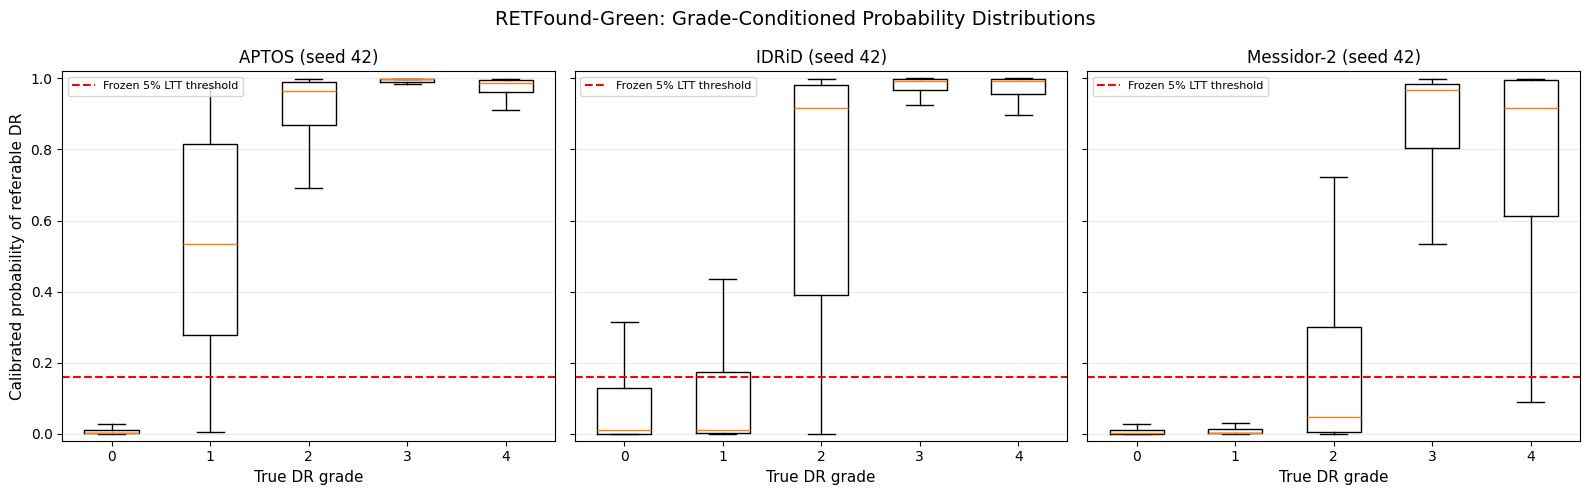


GRADE 2 PROBABILITY DIFFERENCE
IDRiD mean per-seed median: 0.7306
Messidor-2 mean per-seed median: 0.0447
Messidor-2 minus IDRiD: -0.6858

IMPORTANT:
This is descriptive analysis, not proof of the cause of dataset shift.
Whiskers exclude plotted outliers only; all data were used for the statistics.
Five source seeds are not five independent external patient cohorts.

CELL 6 COMPLETE — NOTHING SAVED


In [9]:

# ============================================================
# EXPERIMENT 06 — CELL 6
# GRADE-WISE CALIBRATED PROBABILITY ANALYSIS
#
# Original RETFound-Green predictions
# Frozen APTOS temperatures
# Frozen APTOS 5% LTT thresholds
#
# Table: All five seeds
# Figure: Prespecified seed 42
#
# NO training / NO tuning / NOTHING SAVED
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit

SEEDS = [42, 43, 44, 45, 46]
ALPHA = 0.05
FIGURE_SEED = 42

datasets = {
    "APTOS": aptos_test,
    "IDRiD": idrid_pred,
    "Messidor-2": messidor_pred
}

score_rows = []
score_detail_parts = []

# ============================================================
# 1. RECOMPUTE CALIBRATED PROBABILITIES
# USING ORIGINAL SOURCE-FROZEN PARAMETERS
# ============================================================

for seed in SEEDS:

    T = float(
        temp_data["seeds"][str(seed)]["temperature"]
    )

    policy = ltt[
        (ltt["seed"] == seed)
        & np.isclose(ltt["alpha"], ALPHA)
    ]

    assert len(policy) == 1

    policy = policy.iloc[0]

    assert (
        str(policy["certified"]).strip().lower()
        == "true"
    )

    threshold = float(
        policy["selected_threshold"]
    )

    assert T > 0 and np.isfinite(T)
    assert 0 <= threshold <= 1

    for dataset_name, pred_df in datasets.items():

        df = pred_df[
            pred_df["seed"] == seed
        ].copy()

        # Original RETFound temperature scaling
        df["p_calibrated"] = expit(
            df["raw_logit"].to_numpy(
                dtype=np.float64
            ) / T
        )

        # Original LTT automatic non-referral rule
        df["auto_clear"] = (
            df["p_calibrated"] <= threshold
        )

        df["dataset"] = dataset_name
        df["frozen_threshold"] = threshold

        # Verify against Cell 5 counts
        previous = policy_results[
            (policy_results["dataset"] == dataset_name)
            & (policy_results["seed"] == seed)
        ]

        assert len(previous) == 1

        assert int(df["auto_clear"].sum()) == int(
            previous.iloc[0]["auto_clear_n"]
        )

        assert int(
            (
                df["auto_clear"]
                & (df["binary_label"] == 1)
            ).sum()
        ) == int(
            previous.iloc[0]["referable_errors"]
        )

        # Keep image-level results in memory
        score_detail_parts.append(
            df[
                [
                    "dataset",
                    "seed",
                    "image_id",
                    "original_grade",
                    "binary_label",
                    "raw_logit",
                    "p_calibrated",
                    "frozen_threshold",
                    "auto_clear"
                ]
            ].copy()
        )

        # ================================================
        # 2. GRADE-WISE PROBABILITY STATISTICS
        # ================================================

        for grade in range(5):

            subset = df[
                df["original_grade"] == grade
            ]

            assert len(subset) > 0

            p = subset[
                "p_calibrated"
            ].to_numpy(dtype=np.float64)

            score_rows.append({
                "dataset": dataset_name,
                "seed": seed,
                "grade": grade,
                "n": len(p),

                "mean_probability": float(
                    np.mean(p)
                ),

                "median_probability": float(
                    np.median(p)
                ),

                "q25": float(
                    np.quantile(p, 0.25)
                ),

                "q75": float(
                    np.quantile(p, 0.75)
                ),

                "q10": float(
                    np.quantile(p, 0.10)
                ),

                "q90": float(
                    np.quantile(p, 0.90)
                ),

                "auto_clear_pct": float(
                    100 * subset["auto_clear"].mean()
                )
            })

# ============================================================
# 3. BUILD ANALYSIS DATAFRAMES
# ============================================================

score_results = pd.DataFrame(score_rows)

score_detail = pd.concat(
    score_detail_parts,
    ignore_index=True
)

assert len(score_results) == 75

assert len(score_detail) == (
    len(aptos_test)
    + len(idrid_pred)
    + len(messidor_pred)
)

# ============================================================
# 4. CHECK GRADE-WISE CLEARANCE AGAINST CELL 5
# ============================================================

check = score_results.merge(
    grade_results[
        [
            "dataset",
            "seed",
            "grade",
            "grade_clearance_pct"
        ]
    ],
    on=["dataset", "seed", "grade"],
    validate="one_to_one"
)

assert len(check) == 75

assert np.allclose(
    check["auto_clear_pct"],
    check["grade_clearance_pct"],
    atol=1e-10
)

print("REPRODUCTION CHECK PASSED")
print("All 75 grade/seed clearance rates match Cell 5.")

# ============================================================
# 5. TABLE 2 — SUMMARY ACROSS FIVE SEEDS
#
# Average of five per-seed statistics.
# Do not pool repeated external images as
# independent observations.
# ============================================================

probability_summary = (
    score_results
    .groupby(
        ["dataset", "grade"],
        sort=False
    )
    .agg(
        mean_n=("n", "mean"),

        mean_probability=(
            "mean_probability", "mean"
        ),

        median_probability=(
            "median_probability", "mean"
        ),

        q25=("q25", "mean"),
        q75=("q75", "mean"),

        mean_auto_clear_pct=(
            "auto_clear_pct", "mean"
        )
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("TABLE 2 — GRADE-WISE CALIBRATED PROBABILITIES")
print("Means of per-seed descriptive statistics")
print("=" * 75)

print(
    probability_summary.round(4).to_string(
        index=False
    )
)

# ============================================================
# 6. FOCUSED COMPARISON: GRADE 2
# ============================================================

print("\n" + "=" * 75)
print("GRADE 2 — CROSS-DATASET COMPARISON")
print("=" * 75)

grade2 = probability_summary[
    probability_summary["grade"] == 2
].copy()

print(
    grade2[
        [
            "dataset",
            "mean_n",
            "median_probability",
            "q25",
            "q75",
            "mean_auto_clear_pct"
        ]
    ].round(4).to_string(index=False)
)

# ============================================================
# 7. FIGURE 1 — GRADE-WISE PROBABILITY DISTRIBUTION
#
# Prespecified seed 42, not a selected best seed.
# Same source temperature and threshold are used
# for all three datasets in this figure.
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    sharey=True
)

for ax, dataset_name in zip(
    axes,
    ["APTOS", "IDRiD", "Messidor-2"]
):

    df_plot = score_detail[
        (score_detail["dataset"] == dataset_name)
        & (score_detail["seed"] == FIGURE_SEED)
    ]

    distributions = [
        df_plot.loc[
            df_plot["original_grade"] == grade,
            "p_calibrated"
        ].to_numpy()
        for grade in range(5)
    ]

    ax.boxplot(
        distributions,
        tick_labels=["0", "1", "2", "3", "4"],
        showfliers=False,
        widths=0.55
    )

    frozen_threshold = float(
        df_plot["frozen_threshold"].iloc[0]
    )

    ax.axhline(
        frozen_threshold,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="Frozen 5% LTT threshold"
    )

    ax.set_title(
        f"{dataset_name} (seed {FIGURE_SEED})",
        fontsize=12
    )

    ax.set_xlabel(
        "True DR grade",
        fontsize=11
    )

    ax.set_ylim(-0.02, 1.02)

    ax.grid(
        axis="y",
        alpha=0.25
    )

    ax.legend(
        loc="upper left",
        fontsize=8
    )

axes[0].set_ylabel(
    "Calibrated probability of referable DR",
    fontsize=11
)

fig.suptitle(
    "RETFound-Green: Grade-Conditioned Probability "
    "Distributions",
    fontsize=14
)

plt.tight_layout()
plt.show()

# ============================================================
# 8. EXPLICIT INTERPRETATION AIDS
# ============================================================

g2 = grade2.set_index("dataset")

idrid_median = float(
    g2.loc["IDRiD", "median_probability"]
)

messidor_median = float(
    g2.loc["Messidor-2", "median_probability"]
)

print("\n" + "=" * 75)
print("GRADE 2 PROBABILITY DIFFERENCE")
print("=" * 75)

print(
    "IDRiD mean per-seed median:",
    round(idrid_median, 4)
)

print(
    "Messidor-2 mean per-seed median:",
    round(messidor_median, 4)
)

print(
    "Messidor-2 minus IDRiD:",
    round(messidor_median - idrid_median, 4)
)

print("\nIMPORTANT:")
print(
    "This is descriptive analysis, not proof "
    "of the cause of dataset shift."
)

print(
    "Whiskers exclude plotted outliers only; "
    "all data were used for the statistics."
)

print(
    "Five source seeds are not five independent "
    "external patient cohorts."
)

print("\nCELL 6 COMPLETE — NOTHING SAVED")


#**Final preprocessing sensitivity experiment**

In [10]:

# ============================================================
# EXPERIMENT 06 — CELL 7
# MESSIDOR-2 PREPROCESSING SENSITIVITY
#
# Source: APTOS RETFound notebook, Cell 20
# External: Messidor notebook, Cells 11 and 16
#
# GATE A: Reproduce original saved logits
# GATE B: Reproduce original image embeddings
# FINAL: Change only preprocessing to APTOS method
#
# NO TRAINING / NO RECALIBRATION / NO RE-SPLITTING
# ============================================================

import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "-q",
    "install", "timm==0.9.12"
])

from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.transforms import v2 as T

from scipy.special import expit
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm
import timm

SEEDS = [42, 43, 44, 45, 46]

PROJECT_DIR = Path(PROJECT_DIR)
ROOT = Path("/content/MESSIDOR2/MESSIDOR2")

EMBED_PATH = (
    PROJECT_DIR /
    "messidor2_retfound_green_embeddings.npz"
)

HEAD_PATH = (
    PROJECT_DIR /
    "aptos_retfound_mlp_heads.pt"
)

CHECKPOINT = (
    PROJECT_DIR /
    "retfoundgreen_statedict.pth"
)

OUTPUT_PATH = (
    PROJECT_DIR /
    "messidor2_aptos_preprocess_sensitivity_predictions.csv"
)

# ============================================================
# 1. REQUIRED FILE CHECK
# ============================================================

for label, filepath in {
    "Messidor images": ROOT,
    "Original embeddings": EMBED_PATH,
    "Frozen source heads": HEAD_PATH,
    "RETFound-Green checkpoint": CHECKPOINT
}.items():

    assert filepath.exists(), (
        f"Missing {label}: {filepath}"
    )

assert torch.cuda.is_available(), (
    "Enable GPU in Colab."
)

assert not OUTPUT_PATH.exists(), (
    f"Refusing to overwrite: {OUTPUT_PATH}"
)

# ============================================================
# 2. LOAD ORIGINAL SAVED EMBEDDINGS
# PRESERVE ORIGINAL IMAGE ORDER
# ============================================================

with np.load(
    EMBED_PATH,
    allow_pickle=False
) as data:

    old_X = np.asarray(
        data["embeddings"],
        dtype=np.float32
    )

    image_ids = data["image_id"].astype(str)

    grades = data["original_grade"].astype(int)

    labels = data["binary_label"].astype(int)

assert old_X.shape == (1740, 384)
assert len(set(image_ids)) == 1740
assert np.isfinite(old_X).all()

assert np.array_equal(
    labels,
    (grades >= 2).astype(int)
)

assert all(
    (ROOT / image_id).is_file()
    for image_id in image_ids
)

# ============================================================
# 3. MATCH SAVED ORIGINAL PREDICTIONS
# ============================================================

ref_predictions = {}

for seed in SEEDS:

    r = messidor_pred.loc[
        messidor_pred["seed"] == seed
    ].copy()

    assert not r["image_id"].duplicated().any()

    assert set(
        r["image_id"].astype(str)
    ) == set(image_ids)

    r = (
        r.set_index("image_id")
        .loc[image_ids]
    )

    assert np.array_equal(
        r["original_grade"].to_numpy(dtype=int),
        grades
    )

    assert np.array_equal(
        r["binary_label"].to_numpy(dtype=int),
        labels
    )

    ref_predictions[seed] = r

print("Original 1,740-image cohort verified.")

# ============================================================
# 4. ORIGINAL FROZEN MLP INFERENCE
# 384 -> 512 -> ReLU -> 1
# ============================================================

heads = torch.load(
    HEAD_PATH,
    map_location="cpu",
    weights_only=False
)["heads"]


def head_logits(X, seed):

    state = heads[seed]["state_dict"]

    def single(shape):

        found = [
            v for v in state.values()
            if tuple(v.shape) == shape
        ]

        assert len(found) == 1, (
            f"Seed {seed}: ambiguous shape {shape}"
        )

        return found[0].to(
            dtype=torch.float32,
            device="cpu"
        )

    w1 = single((512, 384))
    b1 = single((512,))
    w2 = single((1, 512))
    b2 = single((1,))

    with torch.inference_mode():

        inp = torch.from_numpy(
            np.ascontiguousarray(
                X,
                dtype=np.float32
            )
        )

        hidden = F.linear(inp, w1, b1)
        hidden = F.relu(hidden)

        logits = F.linear(
            hidden, w2, b2
        ).squeeze(1)

        return logits.numpy()


def fixed_policy(seed):

    temperature = float(
        temp_data["seeds"][str(seed)]["temperature"]
    )

    selection = ltt.loc[
        (ltt["seed"] == seed)
        & np.isclose(ltt["alpha"], 0.05)
    ]

    assert len(selection) == 1

    policy = selection.iloc[0]

    assert (
        str(policy["certified"]).strip().lower()
        == "true"
    )

    threshold = float(
        policy["selected_threshold"]
    )

    assert temperature > 0
    assert np.isfinite(temperature)
    assert 0 <= threshold <= 1

    return temperature, threshold


# ============================================================
# GATE A — REPRODUCE SAVED LOGITS
# ============================================================

print("\n========== GATE A ==========")

for seed in SEEDS:

    logits = head_logits(old_X, seed)

    old_logits = ref_predictions[
        seed
    ]["raw_logit"].to_numpy(dtype=float)

    max_diff = float(
        np.abs(logits - old_logits).max()
    )

    temperature, threshold = fixed_policy(seed)

    old_clear = (
        expit(old_logits / temperature)
        <= threshold
    )

    new_clear = (
        expit(logits / temperature)
        <= threshold
    )

    decision_match = np.array_equal(
        old_clear,
        new_clear
    )

    print(
        f"Seed {seed}: "
        f"Max logit error={max_diff:.7f}, "
        f"decisions match={decision_match}"
    )

    assert max_diff < 0.001
    assert decision_match, (
        "STOP: Original predictions not reproduced."
    )

print("GATE A PASSED")

# ============================================================
# 5. ORIGINAL MESSIDOR PREPROCESSING
# FROM ORIGINAL EXTERNAL NOTEBOOK CELL 11
# ============================================================

original_normalize = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5] * 3,
        std=[0.5] * 3
    )
])


def original_messidor_image(path):

    img = Image.open(path).convert("RGB")

    arr = np.asarray(img)

    mask = np.max(arr, axis=2) > 10

    if mask.any():

        ys, xs = np.where(mask)

        img = img.crop((
            int(xs.min()),
            int(ys.min()),
            int(xs.max()) + 1,
            int(ys.max()) + 1
        ))

    w, h = img.size
    side = max(w, h)

    square = Image.new(
        "RGB",
        (side, side),
        (0, 0, 0)
    )

    square.paste(
        img,
        ((side - w) // 2, (side - h) // 2)
    )

    square = square.resize(
        (392, 392),
        Image.Resampling.LANCZOS
    )

    return original_normalize(square)


# ============================================================
# 6. EXACT ORIGINAL APTOS PREPROCESSING
# FROM SOURCE NOTEBOOK CELL 20
# ============================================================

source_transform = T.Compose([
    T.Resize(
        (392, 392),
        antialias=True
    ),
    T.ToImage(),
    T.ToDtype(
        torch.float32,
        scale=True
    ),
    T.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])


def aptos_preprocess_image(path):

    image = Image.open(path).convert("RGB")

    arr = np.asarray(image)

    gray = (
        0.299 * arr[:, :, 0]
        + 0.587 * arr[:, :, 1]
        + 0.114 * arr[:, :, 2]
    )

    mask = gray > 7

    if mask.any():

        rows = np.where(
            mask.any(axis=1)
        )[0]

        cols = np.where(
            mask.any(axis=0)
        )[0]

        crop = arr[
            rows[0]:rows[-1] + 1,
            cols[0]:cols[-1] + 1
        ]

        image = Image.fromarray(crop)

    w, h = image.size
    side = max(w, h)

    square = Image.new(
        "RGB",
        (side, side),
        (0, 0, 0)
    )

    square.paste(
        image,
        ((side - w) // 2, (side - h) // 2)
    )

    return source_transform(square)


# ============================================================
# 7. DATASET — SAME IMAGES, TWO PREPROCESSING MODES
# ============================================================

class MessidorImages(Dataset):

    def __init__(self, chosen_ids, mode):

        self.ids = chosen_ids

        assert mode in ("original", "source")

        self.mode = mode

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):

        path = ROOT / self.ids[index]

        if self.mode == "original":
            return original_messidor_image(path)

        return aptos_preprocess_image(path)


# ============================================================
# 8. LOAD SAME FROZEN RETFOUND-GREEN
# ============================================================

torch.backends.cuda.matmul.allow_tf32 = False

model = timm.create_model(
    "vit_small_patch14_reg4_dinov2",
    img_size=(392, 392),
    num_classes=0,
    checkpoint_path=str(CHECKPOINT)
)

model.global_pool = "avg"

model = model.to("cuda").eval()

for parameter in model.parameters():
    parameter.requires_grad = False


def extract(chosen, mode, description):

    loader = DataLoader(
        MessidorImages(chosen, mode),
        batch_size=16,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    parts = []

    with torch.inference_mode():

        for batch in tqdm(
            loader,
            desc=description
        ):

            features = model(
                batch.to(
                    "cuda",
                    non_blocking=True
                )
            )

            parts.append(
                features.cpu().numpy()
            )

    return np.concatenate(
        parts
    ).astype(np.float32)


# ============================================================
# GATE B — REPRODUCE ORIGINAL IMAGE EMBEDDINGS
# 20 PREDETERMINED IMAGES, 4 PER GRADE
# ============================================================

sample_indices = []

for grade in range(5):

    positions = np.where(
        grades == grade
    )[0]

    assert len(positions) >= 4

    sample_indices.extend(
        positions[:4].tolist()
    )

sample_ids = image_ids[
    sample_indices
].tolist()

print("\n========== GATE B ==========")

reproduced_X = extract(
    sample_ids,
    "original",
    "Original preprocessing verification"
)

reference_X = old_X[sample_indices]

max_difference = float(
    np.max(
        np.abs(reproduced_X - reference_X)
    )
)

denominator = (
    np.linalg.norm(
        reproduced_X,
        axis=1
    )
    * np.linalg.norm(
        reference_X,
        axis=1
    )
)

cos_sim = (
    np.sum(
        reproduced_X * reference_X,
        axis=1
    )
    / np.maximum(denominator, 1e-12)
)

min_cos = float(cos_sim.min())

print(
    "Maximum embedding absolute error:",
    round(max_difference, 7)
)

print(
    "Minimum cosine similarity:",
    round(min_cos, 8)
)

assert max_difference < 0.005
assert min_cos > 0.99999, (
    "STOP: Original encoder/preprocessing "
    "not reproduced."
)

for seed in SEEDS:

    temperature, threshold = fixed_policy(seed)

    old_logits = (
        ref_predictions[seed]
        .iloc[sample_indices]["raw_logit"]
        .to_numpy(dtype=float)
    )

    new_logits = head_logits(
        reproduced_X,
        seed
    )

    assert np.max(
        np.abs(old_logits - new_logits)
    ) < 0.03

    old_clear = (
        expit(old_logits / temperature)
        <= threshold
    )

    new_clear = (
        expit(new_logits / temperature)
        <= threshold
    )

    assert np.array_equal(
        old_clear,
        new_clear
    ), (
        f"STOP: Original decisions differ "
        f"for seed {seed}"
    )

print("GATE B PASSED")

# ============================================================
# 9. FINAL SENSITIVITY EXPERIMENT
# CHANGE ONLY PREPROCESSING
# ============================================================

print(
    "\n========== PREPROCESSING SENSITIVITY =========="
)

new_X = extract(
    image_ids.tolist(),
    "source",
    "APTOS preprocessing on Messidor-2"
)

assert new_X.shape == old_X.shape
assert np.isfinite(new_X).all()

# ============================================================
# 10. COMPARE ORIGINAL AND NEW RESULTS
# ============================================================

results = []
output_frames = []

for seed in SEEDS:

    temperature, threshold = fixed_policy(seed)

    old_logit = (
        ref_predictions[seed]["raw_logit"]
        .to_numpy(dtype=float)
    )

    new_logit = head_logits(
        new_X,
        seed
    )

    old_clear = (
        expit(old_logit / temperature)
        <= threshold
    )

    new_prob = expit(
        new_logit / temperature
    )

    new_clear = (
        new_prob <= threshold
    )

    def metrics(logit, selected):

        n_clear = int(selected.sum())

        n_errors = int(
            np.sum(
                selected & (labels == 1)
            )
        )

        n_grade2 = int(
            np.sum(
                (grades == 2) & selected
            )
        )

        return {
            "AUROC": roc_auc_score(
                labels, logit
            ),
            "coverage_pct": (
                100 * n_clear / len(labels)
            ),
            "risk_pct": (
                100 * n_errors / n_clear
                if n_clear else np.nan
            ),
            "grade2_miss_pct": (
                100 * n_grade2
                / np.sum(grades == 2)
            ),
            "clear_n": n_clear,
            "errors_n": n_errors
        }

    old_metric = metrics(
        old_logit,
        old_clear
    )

    new_metric = metrics(
        new_logit,
        new_clear
    )

    results.append({
        "seed": seed,
        **{
            f"old_{key}": value
            for key, value in old_metric.items()
        },
        **{
            f"new_{key}": value
            for key, value in new_metric.items()
        }
    })

    output_frames.append(
        pd.DataFrame({
            "image_id": image_ids,
            "original_grade": grades,
            "binary_label": labels,
            "seed": seed,
            "raw_logit": new_logit,
            "p_calibrated": new_prob,
            "auto_clear": new_clear,
            "preprocessing": "APTOS_source_cell20"
        })
    )

# ============================================================
# 11. DISPLAY RESULTS
# ============================================================

summary = pd.DataFrame(results)

print(
    "\n========== ORIGINAL VS APTOS PREPROCESSING =========="
)

print(
    summary.round(3).to_string(index=False)
)

print(
    "\n========== FIVE-SEED MEAN =========="
)

print(
    summary.drop(
        columns="seed"
    ).mean(
        numeric_only=True
    ).round(3).to_string()
)

# ============================================================
# 12. SAVE NEW RESULTS ONLY
# ============================================================

assert not OUTPUT_PATH.exists(), (
    f"Refusing to overwrite: {OUTPUT_PATH}"
)

new_predictions = pd.concat(
    output_frames,
    ignore_index=True
)

assert len(new_predictions) == 8700

new_predictions.to_csv(
    OUTPUT_PATH,
    index=False
)

print("\nNEW results saved:", OUTPUT_PATH)

print(
    "Original predictions and checkpoints unchanged."
)

print("\nCELL 7 COMPLETE")


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


Original 1,740-image cohort verified.

========== GATE A ==========
Seed 42: Max logit error=0.0000000, decisions match=True
Seed 43: Max logit error=0.0000000, decisions match=True
Seed 44: Max logit error=0.0000000, decisions match=True
Seed 45: Max logit error=0.0000000, decisions match=True
Seed 46: Max logit error=0.0000000, decisions match=True
GATE A PASSED

========== GATE B ==========


Original preprocessing verification:   0%|          | 0/2 [00:00<?, ?it/s]

Maximum embedding absolute error: 0.0
Minimum cosine similarity: 0.99999988
GATE B PASSED

========== PREPROCESSING SENSITIVITY ==========


APTOS preprocessing on Messidor-2:   0%|          | 0/109 [00:00<?, ?it/s]


========== ORIGINAL VS APTOS PREPROCESSING ==========
 seed  old_AUROC  old_coverage_pct  old_risk_pct  old_grade2_miss_pct  old_clear_n  old_errors_n  new_AUROC  new_coverage_pct  new_risk_pct  new_grade2_miss_pct  new_clear_n  new_errors_n
   42      0.827            83.103        16.321               65.797         1446           236      0.823            82.816        16.169               64.928         1441           233
   43      0.836            76.609        13.653               52.174         1333           182      0.833            77.011        14.179               53.913         1340           190
   44      0.827            75.517        13.699               51.594         1314           180      0.822            75.057        14.319               53.623         1306           187
   45      0.824            81.092        15.663               61.739         1411           221      0.820            80.690        15.741               62.029         1404           221
   46